**Forward**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
class dense:
    def __init__(self, inputs, neurons):
        self.weights = np.random.randn(inputs, neurons) * np.sqrt(2 / inputs)
        self.biases = np.zeros((1, neurons))
        self.velocity_w = 0
        self.velocity_b = 0
    def forward(self, inputs):
        return np.dot(inputs, self.weights) + self.biases
def relu(input):
    return np.maximum(0, input)
def softmax(inputs):
    exp_values = np.exp(inputs - np.max(inputs, axis=1, keepdims=True))
    return exp_values / np.sum(exp_values, axis=1, keepdims=True)

In [2]:
def cost(y_pred, y_true):
    num_batches = len(y_pred)
    y_pred_clipped = np.clip(y_pred, 0.000001, 1)
    req_prob = y_pred_clipped[range(num_batches), y_true]
    cost= -1 * (np.log(req_prob))
    return cost

In [3]:
input_num = 784
neuron1_num = 64
neuron2_num = 32
batch_size = 64
learning_rate = 0.07
momentum = 0.9
epoch_num = 100

In [4]:
data = np.load("mnist.npz")
train_images = data["x_train"]
train_images = train_images.reshape(-1, 784) / 255.0
train_labels = data["y_train"]

validation_images = train_images[50000:]
validation_labels = train_labels[50000:]
train_images = train_images[:50000]
train_labels = train_labels[:50000]

In [5]:
def backward(label, output, inputs, neuron1, neuron2, layer2, layer3, layer1_linear, layer2_linear):
    batch_size = len(label)
    label_overall = np.zeros([batch_size, 10])
    label_overall[range(batch_size), label] = 1
    d_logits = (output - label_overall) / batch_size
    gradient_w3 = neuron2.T @ d_logits
    gradient_b3 = np.sum(d_logits, axis=0, keepdims=True)
    
    gradient_h2 = d_logits @ (layer3.weights).T
    gradient_h2 *= (layer2_linear > 0)
    gradient_w2 = neuron1.T @ gradient_h2
    gradient_b2 = np.sum((gradient_h2), axis=0, keepdims=True)
    
    gradient_h1 = gradient_h2 @ (layer2.weights).T
    gradient_h1 *= (layer1_linear > 0)
    gradient_w1 = inputs.T @ gradient_h1
    gradient_b1 = np.sum((gradient_h1), axis=0, keepdims=True)
    return gradient_w1, gradient_w2, gradient_w3, gradient_b1, gradient_b2, gradient_b3

def velocity_upd(self, momentum, learning_speed, gradient_w, gradient_b):
    self.velocity_w = (momentum * self.velocity_w) - (learning_speed * gradient_w)
    self.velocity_b = (momentum * self.velocity_b) - (learning_speed * gradient_b)

    self.weights += self.velocity_w
    self.biases += self.velocity_b

In [6]:
layer1 = dense(input_num, neuron1_num)
layer2 = dense(neuron1_num, neuron2_num)
layer3 = dense(neuron2_num, 10)
epoch_loss_history = []
epoch_accuracy_history = []
batch_loss_history = []
batch_accuracy_history = []
validation_accuracy_history = []
best_accuracy = 0

In [7]:
for epoch in range(epoch_num):
    indices = np.random.permutation(len(train_images))
    train_images = train_images[indices]
    train_labels = train_labels[indices]
    losses = []
    accuracies = []
    if epoch > (epoch_num / 6) * 5:
        learning_speed = learning_rate / 4.8
    elif epoch > (epoch_num / 6) * 4:
        learning_speed = learning_rate / 4
    elif epoch > (epoch_num / 6) * 3:
        learning_speed = learning_rate / 3
    elif epoch > (epoch_num / 6) * 2:
        learning_speed = learning_rate / 2.2
    elif epoch > (epoch_num / 6) * 1:
        learning_speed = learning_rate / 1.6
    else:
        learning_speed = learning_rate
    
    for start in range(0, len(train_labels), batch_size):
        end = start + batch_size
        batch_inputs = train_images[start:end]
        batch_labels = train_labels[start:end]
        
        layer1_linear = layer1.forward(batch_inputs)
        neuron1 = relu(layer1_linear)
        layer2_linear = layer2.forward(neuron1)
        neuron2 = relu(layer2_linear)
        output = softmax(layer3.forward(neuron2))
        
        loss = np.mean(cost(output, batch_labels))
        losses.append(loss)
        batch_loss_history.append(loss)
        predictions = np.argmax(output, axis=1)
        correct_predictions = np.sum(predictions == batch_labels)
        total_predictions = len(batch_labels)
        accuracy = (correct_predictions / total_predictions) * 100
        accuracies.append(accuracy)
        batch_accuracy_history.append(accuracy)
        
        gradient_w1, gradient_w2, gradient_w3, gradient_b1, gradient_b2, gradient_b3 = backward(batch_labels, output, batch_inputs, neuron1, neuron2, layer2, layer3, layer1_linear, layer2_linear)

        velocity_upd(layer3, momentum, learning_speed, gradient_w3, gradient_b3)
        velocity_upd(layer2, momentum, learning_speed, gradient_w2, gradient_b2)
        velocity_upd(layer1, momentum, learning_speed, gradient_w1, gradient_b1)

    net_accuracy = np.mean(accuracies)
    net_loss = np.mean(losses)
    epoch_loss_history.append(net_loss)
    epoch_accuracy_history.append(net_accuracy)

    layer1_linear = layer1.forward(validation_images)
    neuron1 = relu(layer1_linear)
    layer2_linear = layer2.forward(neuron1)
    neuron2 = relu(layer2_linear)
    output = softmax(layer3.forward(neuron2))
    predictions = np.argmax(output, axis=1)
    correct_predictions = np.sum(predictions == validation_labels)
    total_predictions = len(validation_labels)
    validation_accuracy = (correct_predictions / total_predictions) * 100
    validation_accuracy_history.append(validation_accuracy)

    if validation_accuracy >= best_accuracy:
        best_accuracy = validation_accuracy
        best_w1 = layer1.weights
        best_b1 = layer1.biases
        best_w2 = layer2.weights
        best_b2 = layer2.biases
        best_w3 = layer3.weights
        best_b3 = layer3.biases
        print("Epoch " + str(epoch + 1) + ": Loss = " + str(net_loss) + "\n         Accuracy = " + str(net_accuracy) + "        Validation Accuracy = " + str(validation_accuracy) + " (Best)")
    else:
        print("Epoch " + str(epoch + 1) + ": Loss = " + str(net_loss) + "\n         Accuracy = " + str(net_accuracy) + "        Validation Accuracy = " + str(validation_accuracy))
layer1.weights = best_w1
layer1.biases = best_b1
layer2.weights = best_w2
layer2.biases = best_b2
layer3.weights = best_w3
layer3.biases = best_b3

Epoch 1: Loss = 0.29919635989906096
         Accuracy = 90.80682544757033        Validation Accuracy = 95.76 (Best)
Epoch 2: Loss = 0.1504182597751231
         Accuracy = 95.42039641943734        Validation Accuracy = 95.99 (Best)
Epoch 3: Loss = 0.11988329424321073
         Accuracy = 96.3914641943734        Validation Accuracy = 95.98
Epoch 4: Loss = 0.10083520457491768
         Accuracy = 96.89897698209718        Validation Accuracy = 96.45 (Best)
Epoch 5: Loss = 0.08895853244606675
         Accuracy = 97.28061061381074        Validation Accuracy = 95.92
Epoch 6: Loss = 0.0789199781892394
         Accuracy = 97.53037084398977        Validation Accuracy = 97.17 (Best)
Epoch 7: Loss = 0.07359671355025423
         Accuracy = 97.7861253196931        Validation Accuracy = 97.1
Epoch 8: Loss = 0.06693030376327806
         Accuracy = 97.89601982097187        Validation Accuracy = 97.11
Epoch 9: Loss = 0.0647051406355887
         Accuracy = 97.97394501278772        Validation Accuracy = 96.

In [8]:
test_size = 10000
test_images = data["x_test"][:test_size]
test_images = test_images.reshape(-1, 784) / 255.0
test_labels = data["y_test"][:test_size]

layer1_linear = layer1.forward(test_images)
neuron1 = relu(layer1_linear)
layer2_linear = layer2.forward(neuron1)
neuron2 = relu(layer2_linear)
output = softmax(layer3.forward(neuron2))

loss = np.mean(cost(output, test_labels))
predictions = np.argmax(output, axis=1)
correct_predictions = np.sum(predictions == test_labels)
total_predictions = len(test_labels)
accuracy = (correct_predictions / total_predictions) * 100
print("Test Size = " + str(test_size) + "    Loss = " + str(loss) + "    Accuracy = " + str(accuracy))

Test Size = 10000    Loss = 0.16034452707662517    Accuracy = 97.77


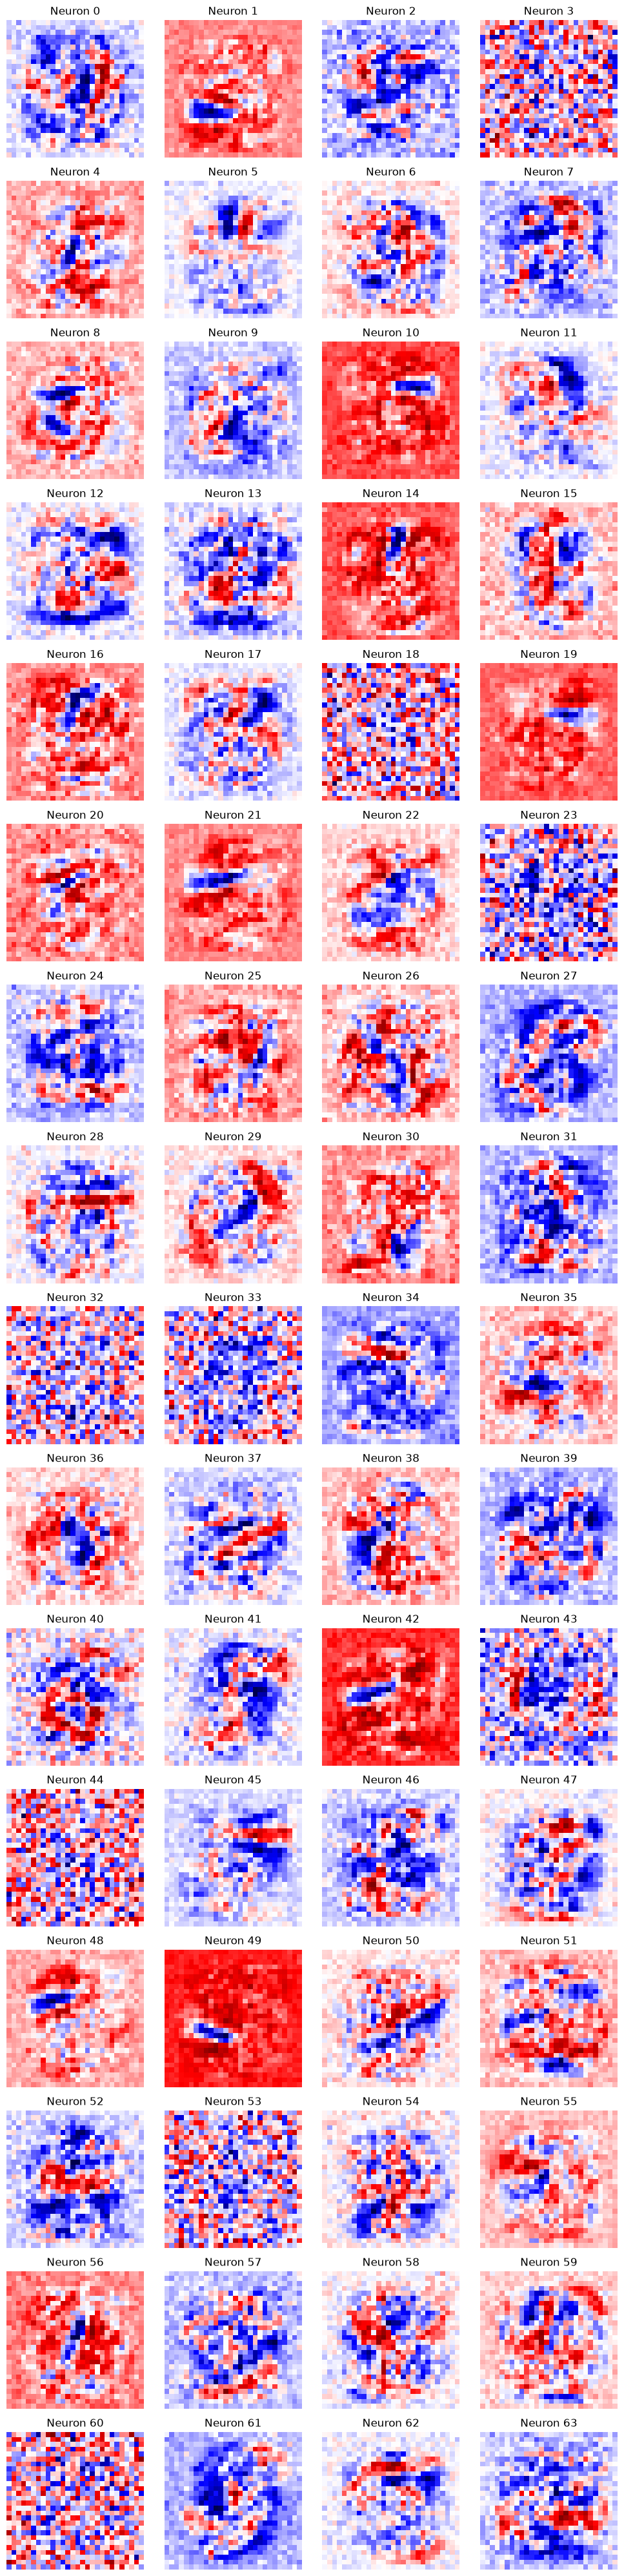

In [9]:
def show_first_layer_weights(layer):

    neurons = layer.weights.shape[1]

    cols = 4
    rows = int(np.ceil(neurons/cols))

    plt.figure(figsize=(10,rows*2.5))

    for i in range(neurons):

        plt.subplot(rows,cols,i+1)

        image = layer.weights[:,i].reshape(28,28)

        plt.imshow(image,cmap="seismic")

        plt.title(f"Neuron {i}")

        plt.axis("off")

    plt.tight_layout()
    plt.show()
show_first_layer_weights(layer1)

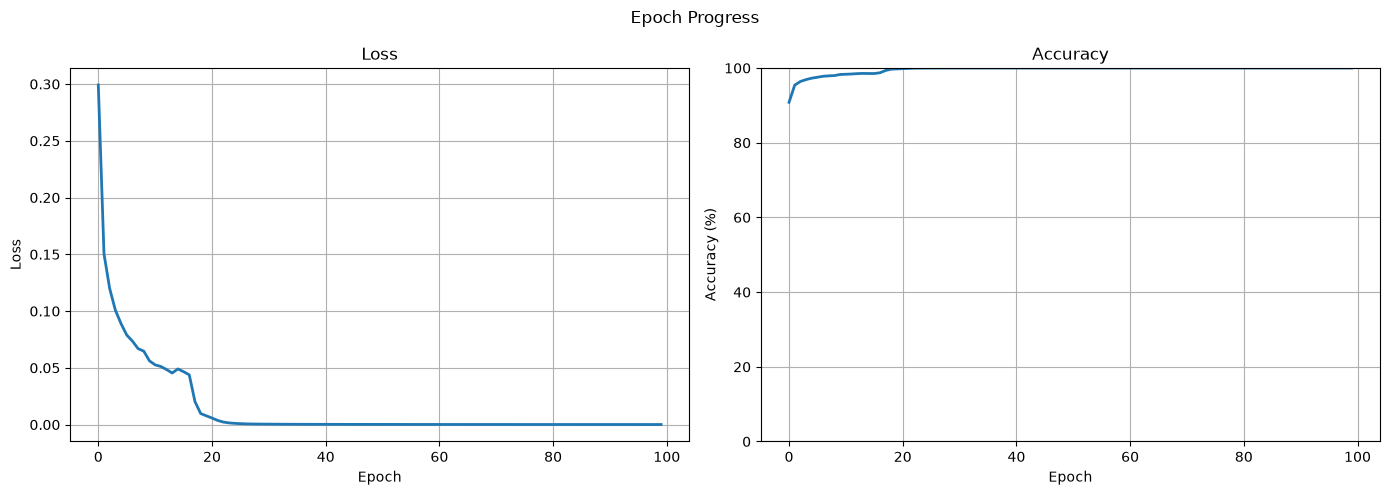

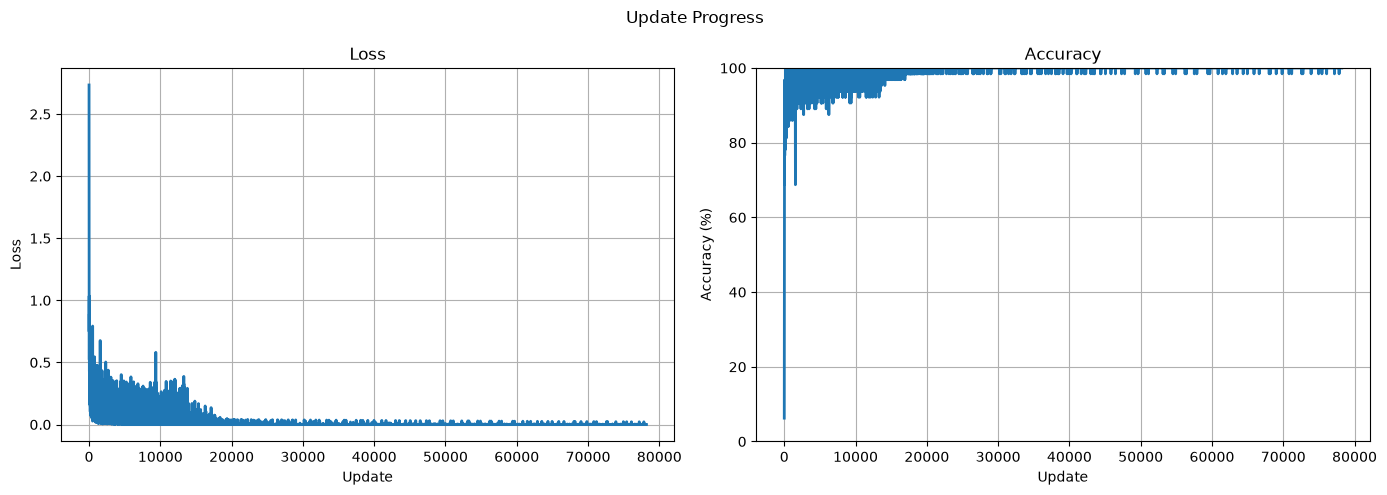

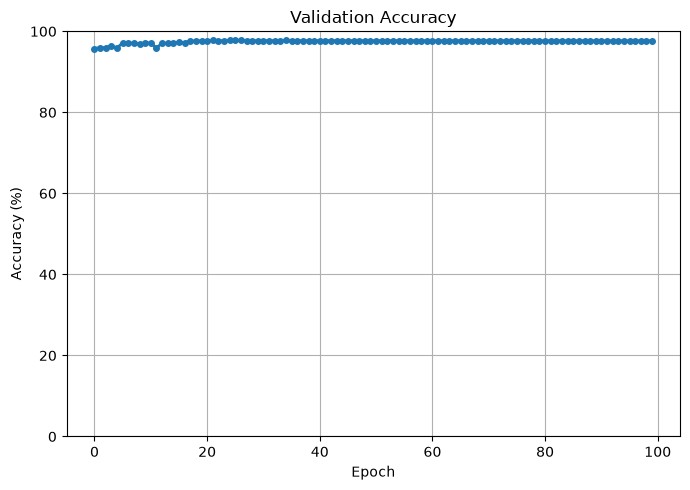

In [10]:
def show_training(loss_history, accuracy_history, title="Training Progress", new_value_point="Epoch"):

    fig, axes = plt.subplots(1, 2, figsize=(14,5))

    # ---------------- Loss ----------------

    axes[0].plot(loss_history, linewidth=2)

    axes[0].set_title("Loss")

    axes[0].set_xlabel(new_value_point)

    axes[0].set_ylabel("Loss")

    axes[0].grid(True)

    # ---------------- Accuracy ----------------

    axes[1].plot(accuracy_history, linewidth=2)

    axes[1].set_title("Accuracy")

    axes[1].set_xlabel(new_value_point)

    axes[1].set_ylabel("Accuracy (%)")

    axes[1].set_ylim(0,100)

    axes[1].grid(True)

    plt.suptitle(title)

    plt.tight_layout()

    plt.show()
    
def show_validation_accuracy(validation_accuracy_history,
                             title="Validation Accuracy",
                             x_label="Epoch"):

    plt.figure(figsize=(7, 5))

    plt.plot(validation_accuracy_history, marker='o', linewidth=2, markersize=4)

    plt.title(title)
    plt.xlabel(x_label)
    plt.ylabel("Accuracy (%)")
    plt.ylim(0, 100)
    plt.grid(True)

    plt.tight_layout()
    plt.show()
    
show_training(epoch_loss_history, epoch_accuracy_history, "Epoch Progress", "Epoch")
show_training(batch_loss_history, batch_accuracy_history, "Update Progress", "Update")
show_validation_accuracy(validation_accuracy_history)